# Spectral information and prior fill-in in RGC-guided diffusion reconstructions

**What this notebook answers.** For a target image $X$, an RGC encoder latent $Z=\mathrm{enc}(X)$, and
reconstructions $Y$ drawn by a diffusion prior guided toward $Z$:

1. **Per spatial frequency, how much information about $X$ survives into $Y$?**
   Measured by magnitude-squared coherence and converted to bits with the Gaussian-channel bound.
2. **Per spatial frequency, how much of $Y$ is invented by the prior rather than determined by $Z$?**
   Measured by the variance across seeds at fixed $Z$.

Because $X \to Z \to Y$ is a Markov chain and guidance uses only $Z$, drawing $K$ seeds at fixed $Z$
separates what the latent pins down from what the prior re-draws each time.

**Two things to keep in mind throughout.**

- Every information number here is a **lower bound** on $I(X;Y)$ under a jointly Gaussian assumption
  (Borst & Theunissen, 1999). Non-linear and non-Gaussian dependence is invisible to coherence, so the
  true mutual information is at least this large and may be considerably larger.
- The sampler is **MAP-flavoured, not a posterior sampler**: guidance is a fixed-magnitude RMS-normalized
  gradient step appended to each DDPM transition. There is no reason to expect it to be calibrated, and
  the calibration section measures exactly how far off it is. Where this notebook says "sample mean" it
  means the mean over seeds, not a posterior mean.

All estimators used here are verified against synthetic data with analytic answers in `tests/`
(110 tests). Run them before trusting anything below.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

from analysis import pipeline as pl
from analysis import plots as pp
from analysis import spectral_fillin as sf

%matplotlib inline
plt.rcParams["figure.dpi"] = 110

# ---------------------------------------------------------------- configuration
BANK = Path("banks/main_n128_k16.npz")      # reconstruction bank to analyse
OUTPUT_DIR = Path("main")                  # where arrays, figures and summary go

WINDOW, TUKEY_ALPHA = "hann", 0.5          # edge-leakage control
N_BINS, N_ORIENT, N_BINS_ORIENTED = 32, 8, 16
N_BOOT, N_SHUFFLES, SEED = 500, 8, 0

# Retinal scale. params.yaml encodes receptive fields as microns/30, implying 30
# microns per pixel, but it never records microns per degree, so the cycles/degree
# axis stays off until that number is supplied.
MICRONS_PER_PIXEL = 30.0
MICRONS_PER_DEGREE = None                  # e.g. 223.0 for macaque; then the axis appears

(OUTPUT_DIR / "figures").mkdir(parents=True, exist_ok=True)

## 1. Load the bank and check the sampler actually ran

Before any spectral work, confirm the guidance loss fell. A reconstruction whose rate mismatch never
drops was not guided toward the latent at all, and its coherence would be measuring the prior alone.

In [2]:
bank = pl.load_bank(BANK)
print(bank.describe())
print("\nsampler configuration:")
print(json.dumps({k: bank.config.get(k) for k in
                  ("model_id", "steps", "guidance_scale", "guidance_normalization",
                   "rate_noise_std", "target_mode", "base_seed")}, indent=2))
print("\nmosaic lattice spacings (pixels):", json.dumps(bank.spacings, indent=2))

CONTENT_LIMIT = (bank.config.get("bandwidth") or {}).get("content_limit_min", 0.5)
print(f"\ntarget content limit: {CONTENT_LIMIT:.4f} cycles/pixel")
print("Above this the targets carry no structure of their own, so S_XX, and any ratio")
print("containing it, is not interpretable there. The fill fraction is unaffected: it uses Y alone.")

main_n128_k16.npz: N=128 targets (128 scenes), K=16 samples, 256x256, 100 steps, guidance=0.0354 (rms), cell types=ON_Parasol, OFF_Parasol, ON_Midget, OFF_Midget

sampler configuration:
{
  "model_id": "google/ddpm-bedroom-256",
  "steps": 100,
  "guidance_scale": 0.0354,
  "guidance_normalization": "rms",
  "rate_noise_std": 1.0,
  "target_mode": "resize",
  "base_seed": 20260301
}

mosaic lattice spacings (pixels): {
  "ON_Parasol": 10.0,
  "OFF_Parasol": 8.333333333333334,
  "ON_Midget": 4.166666666666667,
  "OFF_Midget": 3.3333333333333335
}

target content limit: 0.2871 cycles/pixel
Above this the targets carry no structure of their own, so S_XX, and any ratio
containing it, is not interpretable there. The fill fraction is unaffected: it uses Y alone.


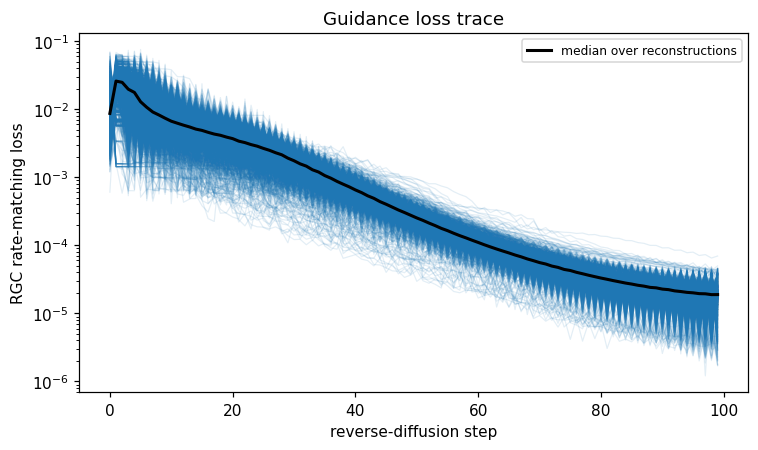

In [3]:
pp.plot_loss_traces(bank);

## 2. Mosaic Nyquist frequencies

A hexagonal mosaic has **no single Nyquist frequency**. The tiling code builds the lattice
$a_1=(s,0)$, $a_2=(s/2, s\sqrt3/2)$ with $s=\texttt{center\_size}/\texttt{coverage\_factor}$
(note: *not* the `base_spacing` key, which the tiling ignores). Its reciprocal lattice is triangular
with spacing $g = 2/(\sqrt3 s)$, and aliasing begins at the first Brillouin zone: a hexagon with

$$f_{\text{Nyq}}^{\min} = \frac{1}{\sqrt3\,s} \quad\text{(zone faces)}, \qquad
  f_{\text{Nyq}}^{\max} = \frac{2}{3 s} \quad\text{(zone corners)},$$

a 15% spread with orientation. The four mosaics differ in spacing by a factor of three, so every
frequency plot carries four markers, not one. They are also interleaved, so the union samples more
densely than any single mosaic: the highest single-mosaic line is a *lower bound* on the union's limit.

In [4]:
nyquist = pl.nyquist_table(bank.spacings)
print(f"{'cell type':<28}{'spacing (px)':>14}{'Nyquist min':>14}{'Nyquist max':>14}")
for name, entry in sorted(nyquist.items(), key=lambda kv: kv[1]["nyquist_min"]):
    print(f"{name:<28}{entry['spacing_pixels']:>14.4f}"
          f"{entry['nyquist_min']:>14.4f}{entry['nyquist_max']:>14.4f}")
# The mosaic that samples most COARSELY has the LOWEST Nyquist frequency, and the
# one that samples most finely has the highest. Naming them by the number rather
# than by the mosaic is an easy way to invert the two, so both are named here.
COARSEST = min(nyquist.items(), key=lambda kv: kv[1]["nyquist_min"])
FINEST = max(nyquist.items(), key=lambda kv: kv[1]["nyquist_min"])
NYQ_LOW, NYQ_HIGH = COARSEST[1]["nyquist_min"], FINEST[1]["nyquist_min"]
print(f"\nlowest  Nyquist: {NYQ_LOW:.4f}  ({COARSEST[0]}, coarsest sampling)")
print(f"highest Nyquist: {NYQ_HIGH:.4f}  ({FINEST[0]}, finest sampling)")

cell type                     spacing (px)   Nyquist min   Nyquist max
ON_Parasol                         10.0000        0.0577        0.0667
OFF_Parasol                         8.3333        0.0693        0.0800
ON_Midget                           4.1667        0.1386        0.1600
OFF_Midget                          3.3333        0.1732        0.2000

lowest  Nyquist: 0.0577  (ON_Parasol, coarsest sampling)
highest Nyquist: 0.1732  (OFF_Midget, finest sampling)


## 3. Preprocessing

Applied **identically** to $X$ and to every $Y$:

1. same normalization (both raw grayscale in $[0,1]$, no per-image rescaling — rescaling would force
   $S_{XX}=S_{YY}$ and destroy the calibration diagnostic);
2. subtract the per-image mean;
3. apply a 2D window, dividing by $U=\langle w^2\rangle$ so total power stays comparable across windows;
4. 2D FFT, DC excluded.

**Mode counting.** A real $H\times W$ image has exactly $HW$ real degrees of freedom and $HW/2$
independent complex modes. Summing $-\tfrac12\log_2(1-\gamma^2)$ over real degrees of freedom on the
full plane is the *same sum* as summing $-\log_2(1-\gamma^2)$ over independent complex modes on one
half-plane, and the full-plane form needs no even/odd special-casing. That equivalence is asserted in
`tests/test_basics.py`.

In [5]:
prepared = pl.prepare(bank, window=WINDOW, alpha=TUKEY_ALPHA, n_bins=N_BINS,
                      n_orient=N_ORIENT, n_bins_oriented=N_BINS_ORIENTED)
scale = dict(microns_per_pixel=MICRONS_PER_PIXEL, microns_per_degree=MICRONS_PER_DEGREE,
             content_limit=CONTENT_LIMIT)

print(f"window={WINDOW}  U=<w^2>={prepared.setup.window_power:.5f}")
print(f"real degrees of freedom per image : {prepared.setup.n_pixels}")
print(f"independent complex modes         : {sf.independent_complex_modes(prepared.setup.shape):.1f}")
print(f"radial bins={prepared.radial.n_bins}  modes binned={int(prepared.radial.dof.sum())}"
      f"  excluded (DC and f>0.5)={prepared.radial.n_excluded}")

window=hann  U=<w^2>=0.13953
real degrees of freedom per image : 65536
independent complex modes         : 32767.5
radial bins=32  modes binned=51430  excluded (DC and f>0.5)=14106


## 4. Analysis 1 — coherence and the information lower bound

Spectra are averaged over images **and** modes within a bin **before** the coherence ratio is formed.
Averaging per-mode coherences instead is biased upward; `tests/test_gaussian_channel.py` asserts that
the biased route really is biased and that this one is not.

Three variants, answering three different questions:

- **$X$ vs $Y_1$** — what a user of the system actually receives.
- **$X$ vs $\bar Y$** — what the latent determines, with sampler noise averaged away. The naive version
  is biased **downward** at finite $K$ because $S_{\bar Y\bar Y} = |\mu|^2 + V/K$; the split-half
  estimator substitutes $S_{\bar Y_A \bar Y_B}$, which is unbiased for $S_{\mu\mu}$. **Prefer the
  debiased curve** — test 6 found the naive one still 17% low at $K=32$.
- **$Y_j$ vs $Y_k$** — what the latent pins down, with no reference to the truth. Equals $(1-F)^2$.

Finite-sample coherence is biased upward, so a shuffle null (derangements pairing $X_n$ with another
image's $Y$) estimates the floor, and intervals come from a bootstrap clustered on source scene.

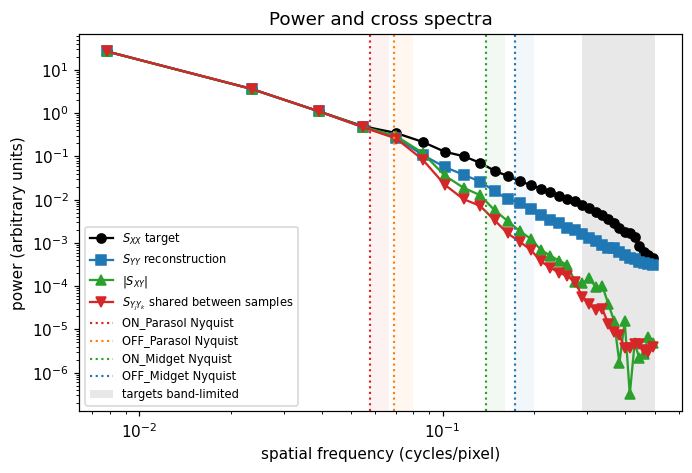

In [6]:
coherence = pl.run_coherence(prepared, n_boot=N_BOOT, n_shuffles=N_SHUFFLES, seed=SEED, cluster=True)
pp.plot_spectra(coherence, nyquist, **scale);

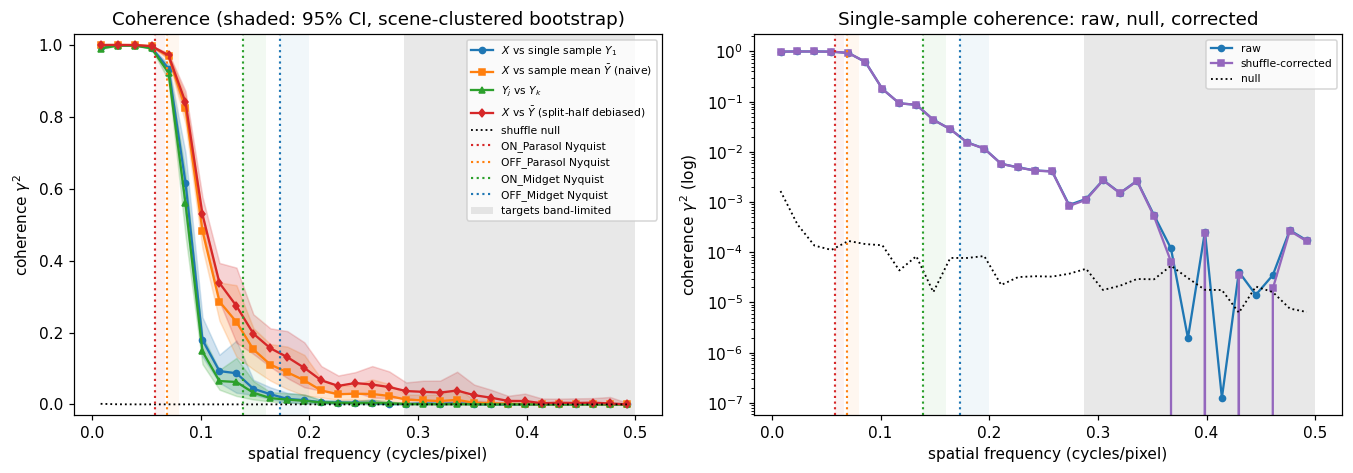

In [7]:
pp.plot_coherence(coherence, nyquist, **scale);

single sample Y_1           4980.0 bits/image    0.0760 bits/pixel
sample mean (naive)         7132.9 bits/image    0.1088 bits/pixel
single, shuffle-corrected    4904.7 bits/image
sample mean (debiased)      8063.7 bits/image

All of these are Gaussian-channel LOWER bounds on I(X;Y).


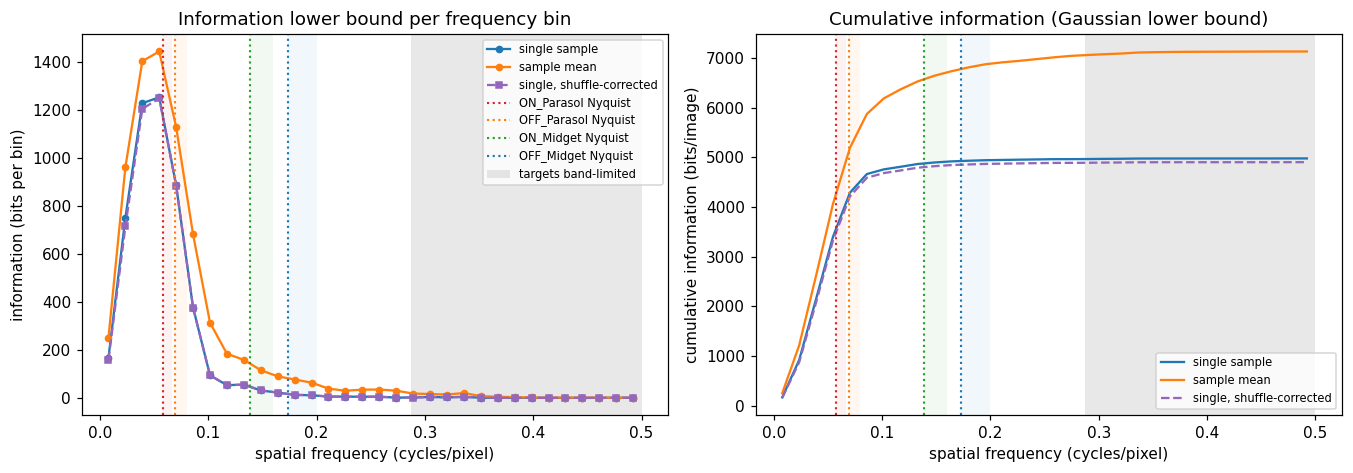

In [8]:
pp.plot_information(coherence, nyquist, **scale)

height, width = prepared.setup.shape
for key, name in [("single", "single sample Y_1"), ("mean", "sample mean (naive)")]:
    total = coherence[key]["total_bits"]
    print(f"{name:<24}{total:10.1f} bits/image   {total / (height * width):7.4f} bits/pixel")
print(f"{'single, shuffle-corrected':<24}{coherence['single']['total_bits_corrected']:10.1f} bits/image")
if coherence["mean_debiased"]:
    print(f"{'sample mean (debiased)':<24}{coherence['mean_debiased']['total_bits']:10.1f} bits/image")
print("\nAll of these are Gaussian-channel LOWER bounds on I(X;Y).")

## 5. Analysis 2 — empirical fill-in

$V_{\text{fill}}(f) = \mathrm{Var}_k(\hat Y_k(f))$ with the $K/(K-1)$ correction: the part of the
reconstruction the latent does not fix, which the prior supplies anew on every seed. It is **unbiased at
every $K\ge2$**; $K$ buys precision, not accuracy.

Two identities are checked numerically rather than assumed:

$$S_{YY} = \mathrm{Var}_n(E[\hat Y|Z]) + E_n[\mathrm{Var}(\hat Y|Z)], \qquad
E|\hat X-\hat Y_k|^2 = E|\hat X-\bar Y|^2 + E\,\mathrm{Var}(\hat Y|Z).$$

Both need the finite-$K$ correction to close; the residuals below should be at machine precision
relative to the power in the bin.

law of total variance, max relative residual : 1.12e-15
error decomposition,  max relative residual : 5.61e-15

crossover (F = 0.5): 0.0966 cycles/pixel
  = 1.67 x the lowest  mosaic Nyquist (ON_Parasol, 0.0577)
  = 0.56 x the highest mosaic Nyquist (OFF_Midget, 0.1732)


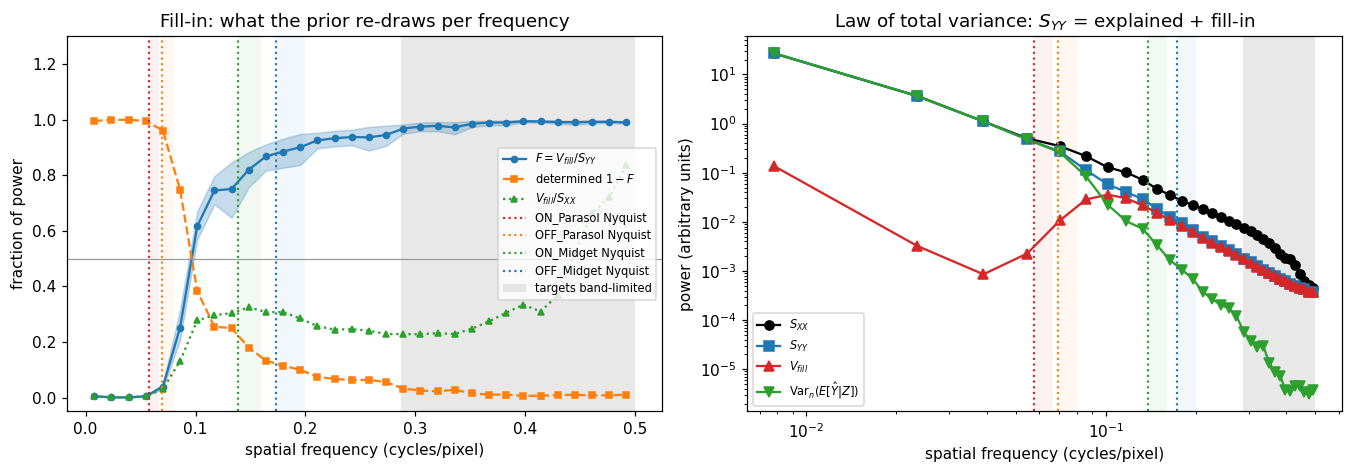

In [9]:
fill = pl.run_fill(prepared, n_boot=N_BOOT, seed=SEED, cluster=True)
pp.plot_fill_curves(fill, nyquist, **scale)

print(f"law of total variance, max relative residual : {fill['total_variance_max_relative_residual']:.2e}")
print(f"error decomposition,  max relative residual : {fill['error_max_relative_residual']:.2e}")

crossover = pl.crossover_frequency(fill["f_centers"], fill["fill_fraction"])
print(f"\ncrossover (F = 0.5): {crossover:.4f} cycles/pixel")
print(f"  = {crossover / NYQ_LOW:.2f} x the lowest  mosaic Nyquist ({COARSEST[0]}, {NYQ_LOW:.4f})")
print(f"  = {crossover / NYQ_HIGH:.2f} x the highest mosaic Nyquist ({FINEST[0]}, {NYQ_HIGH:.4f})")

### Error decomposition, and a free calibration diagnostic

If the sampler were an exact posterior sampler, $X$ and $Y_k$ would be exchangeable given $Z$, forcing
$E|\hat X-\hat Y|^2 = 2\,\mathrm{Var}(\hat Y|Z)$ at **every** frequency — the target is then just another
posterior draw. The fill-in share of squared error would be the frequency-independent constant
$(K-1)/2K$. A sampler that is too smooth falls below that line at high frequency.

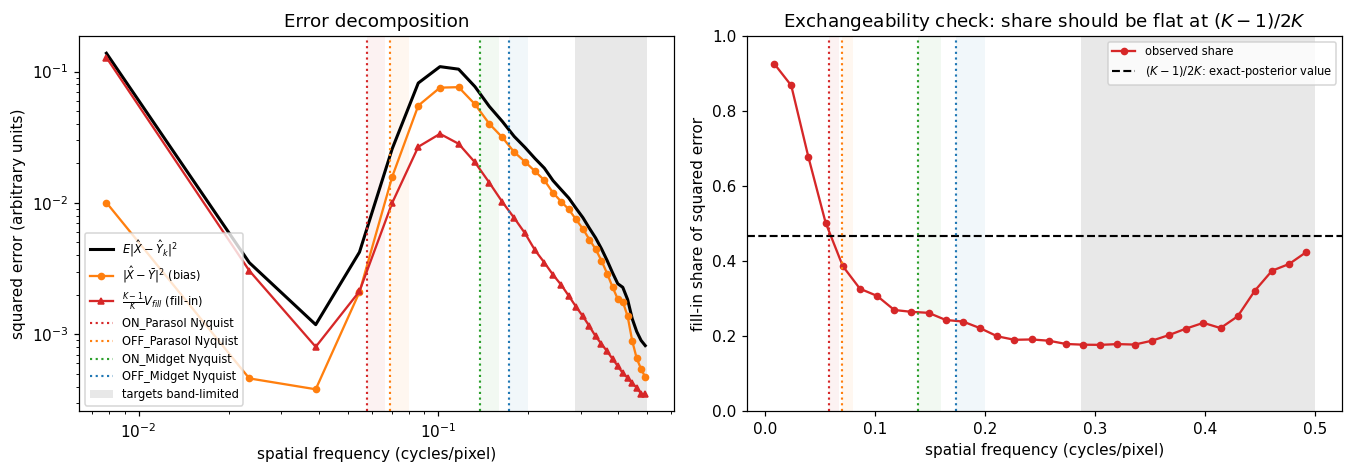

In [10]:
pp.plot_error_decomposition(fill, nyquist, **scale);

## 6. Calibration — is the sampler exchangeable with the truth?

Two consequences of exchangeability, per bin:

- $S_{XX} = S_{YY}$. Ratio $<1$: the sampler under-expresses power (too smooth). $>1$: it injects more
  than the prior would.
- $S_{XY} = S_{Y_jY_k}$. Ratio $<1$: two samples agree with each other *more* than either agrees with
  the truth — a shared bias the latent did not ask for.

**The two are not redundant, and each is blind to a different failure.** On the synthetic toy
(`tests/test_miscalibration.py`), scaling the posterior *noise* by 0.5 or 2 moves the power ratio in the
correct direction while leaving the cross ratio at exactly 1.00; scaling the posterior *mean* by $g$
(wrong guidance strength) drives the cross ratio to $1/g$. Read both.

The cross ratio degenerates where the latent determines nothing: $S_{XY}$ and $S_{Y_jY_k}$ are then both
consistent with zero and their ratio wanders over orders of magnitude. Those bins are masked.

S_YY/S_XX   median overall (below content limit) : 0.354
            median below lowest Nyquist          : 1.001
            median above lowest Nyquist          : 0.305
|S_XY|/S_YjYk median over 18 reliable bins : 1.730


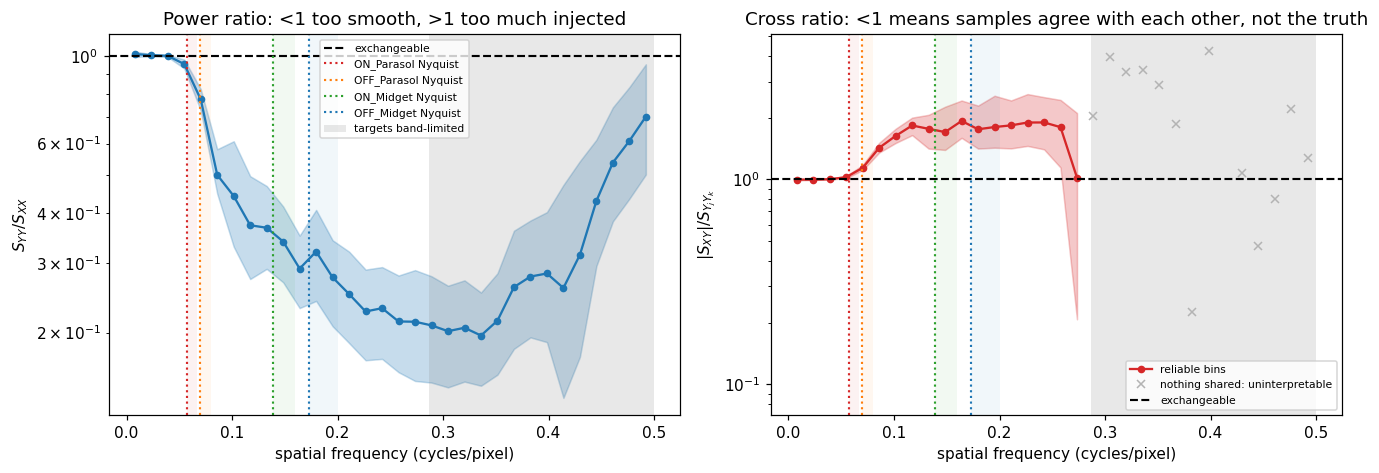

In [11]:
calibration = pl.run_calibration(prepared, n_boot=N_BOOT, seed=SEED, cluster=True)
pp.plot_calibration(calibration, nyquist, **scale)

f = calibration["f_centers"]
usable = f <= CONTENT_LIMIT
low, high = usable & (f <= NYQ_LOW), usable & (f > NYQ_LOW)
print(f"S_YY/S_XX   median overall (below content limit) : {np.nanmedian(calibration['ratio_power'][usable]):.3f}")
print(f"            median below lowest Nyquist          : {np.nanmedian(calibration['ratio_power'][low]):.3f}")
print(f"            median above lowest Nyquist          : {np.nanmedian(calibration['ratio_power'][high]):.3f}")
mask = calibration["reliable"] & usable
if mask.any():
    print(f"|S_XY|/S_YjYk median over {int(mask.sum())} reliable bins : "
          f"{np.nanmedian(calibration['ratio_cross_raw'][mask]):.3f}")

## 7. Orientation-resolved analysis

A hexagonal mosaic resolves ~15% more along the directions pointing at its Brillouin-zone corners than
along those pointing at the zone faces. The overlaid hexagons are those boundaries. With four mosaics at
different spacings and offsets, any single-mosaic anisotropy is largely washed out in the union.

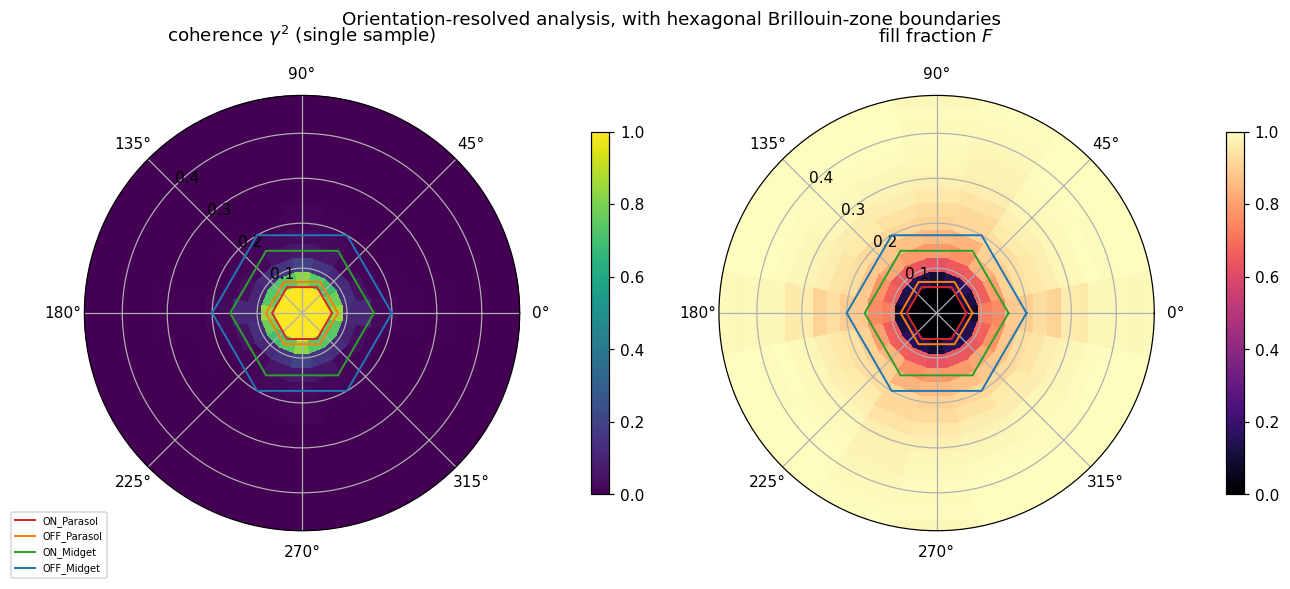

In [12]:
oriented = pl.run_oriented(prepared)
pp.plot_oriented(oriented, bank.spacings);

## 8. Pixel space and per-image scores

Where in the image does the prior do its inventing, and which images does it invent most of?

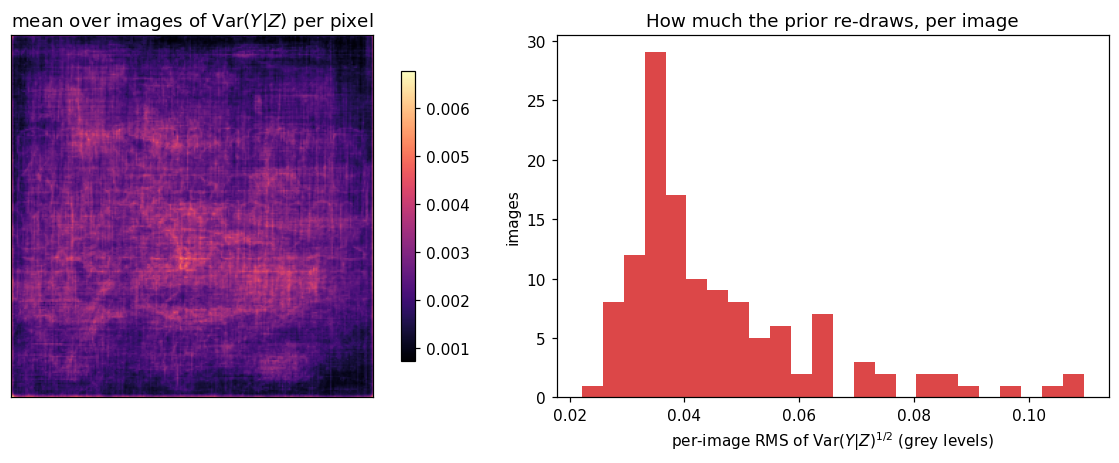

In [13]:
pp.plot_pixel_maps(fill);

rows: most determined, median, most filled in


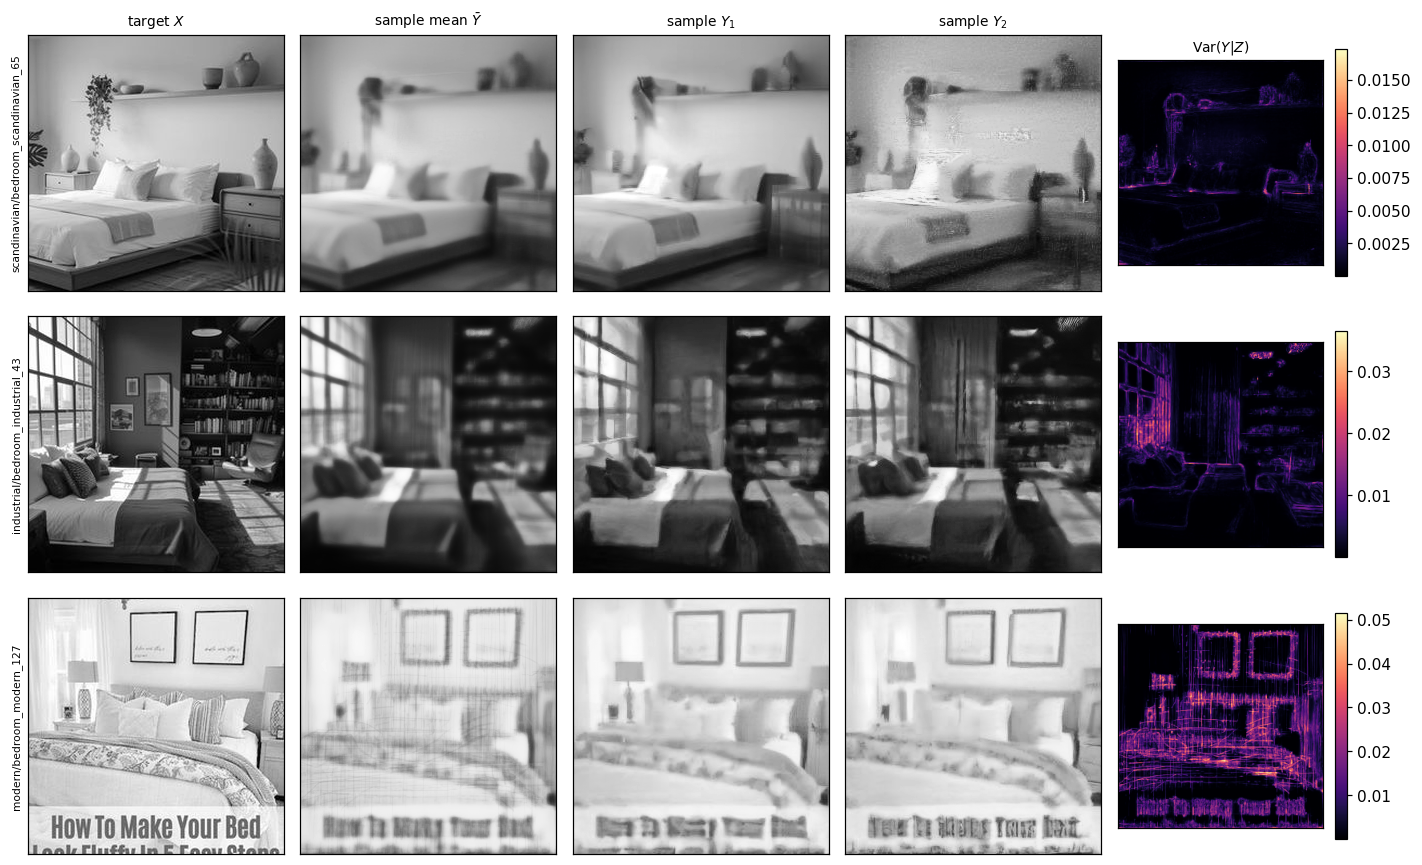

In [14]:
per_image = pl.run_per_image(prepared, cutoff=NYQ_LOW)
order = per_image["order"]
pp.plot_examples(bank, fill, [int(order[0]), int(order[len(order) // 2]), int(order[-1])])
print("rows: most determined, median, most filled in")

most determined (lowest fill fraction):
  scandinavian/bedroom_scandinavian_65    0.0157
  modern/bedroom_modern_139               0.0171
  minimalist/bedroom_minimalist_21        0.0183
  boho/bedroom_boho_133                   0.0206
  industrial/bedroom_industrial_194       0.0238
most filled in:
  modern/bedroom_modern_127               0.5744
  scandinavian/bedroom_scandinavian_34    0.4732
  industrial/bedroom_industrial_179       0.4273
  modern/bedroom_modern_28                0.3821
  minimalist/bedroom_minimalist_159       0.3770


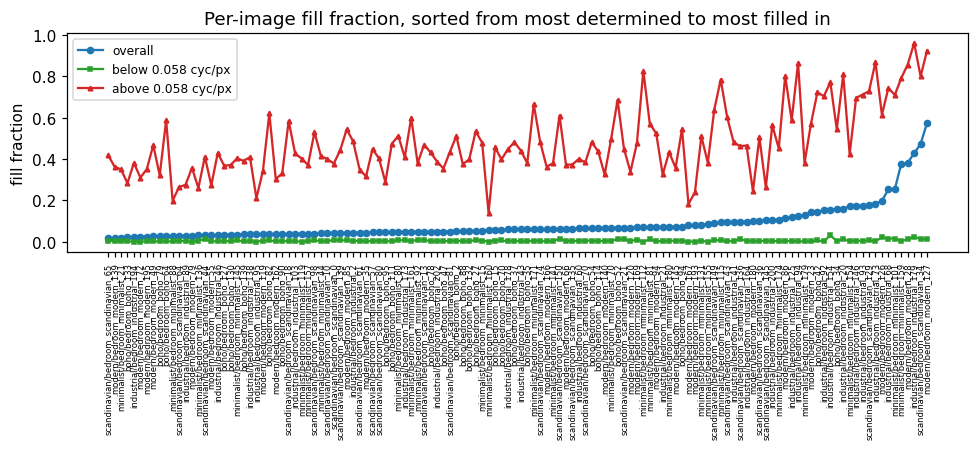

In [15]:
pp.plot_per_image_scores(per_image)
print("most determined (lowest fill fraction):")
for i in order[:5]:
    print(f"  {str(per_image['labels'][i]):<40}{per_image['fill_overall'][i]:.4f}")
print("most filled in:")
for i in order[-5:][::-1]:
    print(f"  {str(per_image['labels'][i]):<40}{per_image['fill_overall'][i]:.4f}")

## 9. Save arrays, figures, and the summary

In [16]:
figures = {
    "spectra": pp.plot_spectra(coherence, nyquist, **scale),
    "coherence": pp.plot_coherence(coherence, nyquist, **scale),
    "information": pp.plot_information(coherence, nyquist, **scale),
    "fill_curves": pp.plot_fill_curves(fill, nyquist, **scale),
    "error_decomposition": pp.plot_error_decomposition(fill, nyquist, **scale),
    "calibration": pp.plot_calibration(calibration, nyquist, **scale),
    "oriented": pp.plot_oriented(oriented, bank.spacings),
    "pixel_maps": pp.plot_pixel_maps(fill),
    "per_image_scores": pp.plot_per_image_scores(per_image),
    "loss_traces": pp.plot_loss_traces(bank),
    "examples": pp.plot_examples(bank, fill,
                                 [int(order[0]), int(order[len(order) // 2]), int(order[-1])]),
}
for name, figure in figures.items():
    figure.savefig(OUTPUT_DIR / "figures" / f"{name}.png", dpi=150)
    plt.close(figure)

arrays = pl.collect_arrays(coherence=coherence, fill=fill, calibration=calibration,
                           oriented=oriented, per_image=per_image)
arrays["radial/f_centers"] = prepared.radial.f_centers
arrays["radial/f_edges"] = prepared.radial.f_edges
arrays["radial/dof"] = prepared.radial.dof
arrays["oriented/theta_centers"] = prepared.oriented.theta_centers
np.savez_compressed(OUTPUT_DIR / "spectral_fillin_results.npz", **arrays)

summary = pl.build_summary(bank, prepared, coherence, fill, calibration, per_image, nyquist)
summary["preprocessing"].update(window=WINDOW, tukey_alpha=TUKEY_ALPHA,
                                n_radial_bins=N_BINS, bootstrap="scene-clustered",
                                n_bootstrap=N_BOOT)
(OUTPUT_DIR / "summary.json").write_text(json.dumps(summary, indent=2))
print(f"wrote {len(figures)} figures, spectral_fillin_results.npz, summary.json to {OUTPUT_DIR}/")

wrote 11 figures, spectral_fillin_results.npz, summary.json to main/


In [17]:
print(json.dumps({
    "crossover_cycles_per_pixel": summary["fill_in"]["crossover_frequency_cycles_per_pixel"],
    "crossover_relative_to_lowest_nyquist": summary["fill_in"]["crossover_relative_to_coarsest_mosaic_nyquist"],
    "bits_per_image_single_sample": summary["information"]["single_sample_total_bits_per_image"],
    "bits_per_pixel_single_sample": summary["information"]["single_sample_bits_per_pixel"],
    "power_ratio_median": summary["calibration"]["power_ratio_median"],
    "cross_ratio_median": summary["calibration"]["cross_ratio_median_where_reliable"],
}, indent=2))

{
  "crossover_cycles_per_pixel": 0.09657947613313676,
  "crossover_relative_to_lowest_nyquist": 1.6728055963097863,
  "bits_per_image_single_sample": 4980.03481926596,
  "bits_per_pixel_single_sample": 0.0759893008310846,
  "power_ratio_median": 0.3022473655397918,
  "cross_ratio_median": 1.7296106997777445
}
